# Null and Alternative Hypotheses

Companion notebook for [notes/hypothesis_testing_and_confidence_intervals/null_hypothesis.md](../../notes/hypothesis_testing_and_confidence_intervals/null_hypothesis.md).

The null hypothesis $H_0$ specifies a model against which the data are compared. The p-value is the probability, *assuming $H_0$*, of a statistic at least as extreme as the one observed. This notebook builds that idea from exact computation, then simulation, then the duality with confidence intervals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(7)

## 1. The marble-bag example

Under $H_0$ (Bag A, half black), the probability that $n$ draws are all black is $0.5^n$. The p-value falls geometrically.

In [2]:
for n in range(1, 9):
    print(f"n={n}: p = {0.5 ** n:.5f}")
alpha = 0.05
n_needed = int(np.ceil(np.log(alpha) / np.log(0.5)))
print(f"Smallest n with p <= {alpha}: {n_needed}")

n=1: p = 0.50000
n=2: p = 0.25000
n=3: p = 0.12500
n=4: p = 0.06250
n=5: p = 0.03125
n=6: p = 0.01562
n=7: p = 0.00781
n=8: p = 0.00391
Smallest n with p <= 0.05: 5


## 2. Exact binomial p-value for a coin

10 tosses, 4 heads, $H_0:p=0.5$ (two-sided). The p-value adds all outcomes with probability no larger than the observed one.

P(X=4) = 0.20508
Two-sided p-value = 0.7539
scipy binomtest: 0.7539


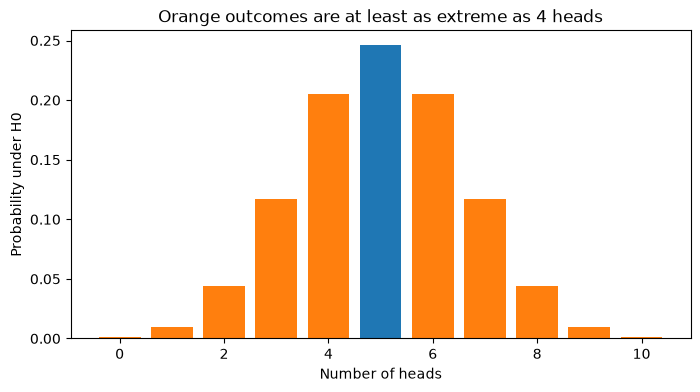

In [3]:
n, k, p0 = 10, 4, 0.5
pmf = stats.binom.pmf(np.arange(n + 1), n, p0)
p_obs = pmf[k]
p_value = pmf[pmf <= p_obs + 1e-12].sum()
print(f"P(X=4) = {p_obs:.5f}")
print(f"Two-sided p-value = {p_value:.4f}")
print("scipy binomtest:", round(stats.binomtest(k, n, p0).pvalue, 4))

plt.figure(figsize=(8, 4))
colors = ["tab:orange" if pmf[i] <= p_obs + 1e-12 else "tab:blue" for i in range(n + 1)]
plt.bar(range(n + 1), pmf, color=colors)
plt.xlabel("Number of heads")
plt.ylabel("Probability under H0")
plt.title("Orange outcomes are at least as extreme as 4 heads")
plt.show()

The result (about 0.754) is far from small, so 4 heads in 10 tosses gives no evidence against fairness. This is not proof the coin is fair.

## 3. p-values from simulation

We can approximate the same p-value by simulating the null model many times and counting how often the statistic is as extreme as observed.

In [4]:
sims = rng.binomial(n, p0, size=200_000)
extreme = np.abs(sims - n * p0) >= abs(k - n * p0)
print(f"Simulated two-sided p-value: {extreme.mean():.4f}")

Simulated two-sided p-value: 0.7548


## 4. p-values are uniform when $H_0$ is true

If $H_0$ holds, a well-calibrated test produces p-values spread uniformly on $[0,1]$, so a fraction $\alpha$ fall below $\alpha$. This is why $\alpha$ is the Type I error rate.

Fraction of p-values <= 0.05: 0.051


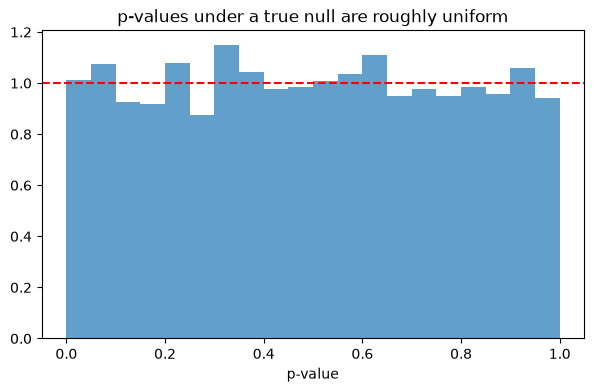

In [5]:
pvals = np.array([
    stats.ttest_1samp(rng.normal(0, 1, 30), 0.0).pvalue for _ in range(5000)
])
print(f"Fraction of p-values <= 0.05: {np.mean(pvals <= 0.05):.3f}")

plt.figure(figsize=(7, 4))
plt.hist(pvals, bins=20, density=True, alpha=0.7)
plt.axhline(1.0, color="red", linestyle="--")
plt.xlabel("p-value")
plt.title("p-values under a true null are roughly uniform")
plt.show()

## 5. Tests and intervals agree

For the two-sided one-sample t-test, $H_0:\mu=\mu_0$ is rejected at level $\alpha$ exactly when $\mu_0$ lies outside the $(1-\alpha)$ interval.

In [6]:
data = rng.normal(0.4, 1, 40)
res = stats.ttest_1samp(data, 0.0)
ci = res.confidence_interval(0.95)
print(f"p = {res.pvalue:.4f}, 95% CI = ({ci.low:.3f}, {ci.high:.3f})")
print("0 inside CI:", ci.low <= 0 <= ci.high, "| reject at 5%:", res.pvalue <= 0.05)

p = 0.0004, 95% CI = (0.299, 0.941)
0 inside CI: False | reject at 5%: True
